[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jseborga/recursos-ia/blob/main/notebooks/01_verificacion_taller.ipynb)

# Verificación independiente de los recursos del taller

**Módulo 8 · El auxiliar aumentado** (Curso de Actualización Pedagógica en Tiempos de la IA, FCPN).

Las dos páginas web del taller, la simulación de tiro parabólico y el banco de problemas, se generaron con IA. Este cuaderno las comprueba **con otro lenguaje y otro método numérico**. Si dos implementaciones independientes coinciden, la probabilidad de un error compartido es mucho menor.

**Cómo usarlo:** menú *Entorno de ejecución → Ejecutar todo*. Cada control termina en `✔` o detiene el cuaderno con un mensaje que explica qué no coincide.

Nada de este cuaderno modifica el repositorio: Colab abre una copia editable.

## Parte 1 · Tiro parabólico con arrastre cuadrático

Modelo (el mismo que usa la página web):

$$m\,\frac{d\vec v}{dt} = -m g\,\hat y - \tfrac12\,\rho\,C_d\,A\,|\vec v|\,\vec v$$

La página integra con Runge–Kutta 4 de paso fijo, escrito en JavaScript. Aquí se usa `scipy.integrate.solve_ivp` (Runge–Kutta 4(5) con paso adaptativo) y un **evento** que detecta el impacto en $y = 0$. Son implementaciones independientes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parámetros de la página web (mismos valores por defecto)
OBJETOS = {
    "tenis":    dict(m=0.057,  d=0.067, cd=0.55),
    "futbol":   dict(m=0.43,   d=0.22,  cd=0.25),
    "pingpong": dict(m=0.0027, d=0.040, cd=0.50),
    "acero":    dict(m=0.110,  d=0.030, cd=0.47),
}
LUGARES = {
    "La Paz (~3640 m)": dict(rho=0.85,  g=9.773),
    "Nivel del mar":    dict(rho=1.225, g=9.807),
}

def analitico(v0, th_deg, h0, g):
    """Alcance, altura máxima y tiempo de vuelo en el vacío."""
    th = np.radians(th_deg)
    vx, vy = v0*np.cos(th), v0*np.sin(th)
    T = (vy + np.sqrt(vy**2 + 2*g*h0)) / g
    return dict(R=vx*T, H=h0 + vy**2/(2*g), T=T)

def numerico(v0, th_deg, h0, g, rho, m, d, cd):
    """Integra con solve_ivp (RK45 adaptativo) hasta que y = 0."""
    k = 0.5*rho*cd*np.pi*(d/2)**2/m          # k = ρ·Cd·A / (2m)
    def f(t, s):
        x, y, vx, vy = s
        v = np.hypot(vx, vy)
        return [vx, vy, -k*v*vx, -g - k*v*vy]
    def suelo(t, s):
        return s[1]
    suelo.terminal, suelo.direction = True, -1
    th = np.radians(th_deg)
    s0 = [0, h0, v0*np.cos(th), v0*np.sin(th)]
    sol = solve_ivp(f, (0, 200), s0, events=suelo, rtol=1e-10, atol=1e-12, dense_output=True)
    T = sol.t_events[0][0]
    t = np.linspace(0, T, 400)
    x, y = sol.sol(t)[:2]
    return dict(R=sol.y_events[0][0][0], H=y.max(), T=T, x=x, y=y, k=k)

print("Funciones listas.")

Funciones listas.


### Control 1 · Caso límite: sin aire debe coincidir con la fórmula analítica

Si el integrador está bien, con $\rho = 0$ el alcance numérico y $R = v_0\cos\theta \cdot T$ deben coincidir casi exactamente.

In [2]:
v0, th, h0 = 25, 45, 0
for h in (0, 10):
    a = analitico(v0, th, h, 9.773)
    n = numerico(v0, th, h, 9.773, rho=0, **OBJETOS["tenis"])
    err = abs(n["R"] - a["R"]) / a["R"]
    print(f"h0 = {h:>2} m   analítico = {a['R']:.6f} m   numérico = {n['R']:.6f} m   error relativo = {err:.1e}")
    assert err < 1e-6, "El integrador no reproduce el caso sin aire: revisar las ecuaciones."
print("✔ Control 1 superado")

h0 =  0 m   analítico = 63.951704 m   numérico = 63.951704 m   error relativo = 4.4e-16
h0 = 10 m   analítico = 72.743144 m   numérico = 72.743144 m   error relativo = 0.0e+00
✔ Control 1 superado


### Control 2 · ¿Coincide con lo que muestra la página web?

Valores que muestra la simulación web para una pelota de tenis a 25 m/s, 45°, desde el suelo. Si alguien modifica la página, actualice esta tabla con lo que ve en pantalla y vuelva a ejecutar.

In [3]:
VALORES_WEB = {          # alcance en metros, tal como lo muestra la tabla de la página
    ("vacío", "La Paz (~3640 m)"): 63.95,
    ("aire",  "La Paz (~3640 m)"): 38.77,
    ("aire",  "Nivel del mar"):    33.48,
}
TOL = 0.005   # 0,5 %: la web redondea a 2 decimales e integra con paso fijo

for (caso, lugar), web in VALORES_WEB.items():
    L = LUGARES[lugar]
    if caso == "vacío":
        R = analitico(25, 45, 0, L["g"])["R"]
    else:
        R = numerico(25, 45, 0, L["g"], L["rho"], **OBJETOS["tenis"])["R"]
    dif = abs(R - web) / web
    estado = "✔" if dif < TOL else "✘"
    print(f"{estado} {caso:<5} {lugar:<18} Python = {R:7.3f} m   web = {web:6.2f} m   diferencia = {dif*100:.3f} %")
    assert dif < TOL, f"La web y Python no coinciden en: {caso}, {lugar}"
print("✔ Control 2 superado: dos implementaciones independientes coinciden")

✔ vacío La Paz (~3640 m)   Python =  63.952 m   web =  63.95 m   diferencia = 0.003 %
✔ aire  La Paz (~3640 m)   Python =  38.774 m   web =  38.77 m   diferencia = 0.011 %
✔ aire  Nivel del mar      Python =  33.483 m   web =  33.48 m   diferencia = 0.009 %
✔ Control 2 superado: dos implementaciones independientes coinciden


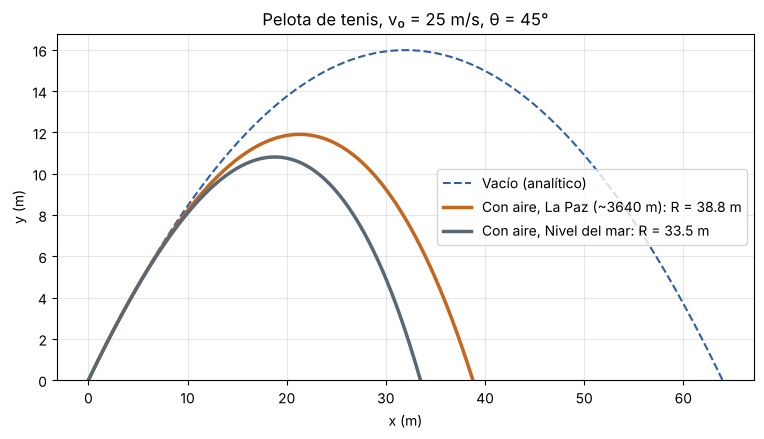

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
a = analitico(25, 45, 0, 9.773)
t = np.linspace(0, a["T"], 200)
ax.plot(25*np.cos(np.pi/4)*t, 25*np.sin(np.pi/4)*t - 9.773*t**2/2, "--", color="#2f5fa8", label="Vacío (analítico)")
for lugar, color in [("La Paz (~3640 m)", "#c4661c"), ("Nivel del mar", "#5a6873")]:
    L = LUGARES[lugar]
    n = numerico(25, 45, 0, L["g"], L["rho"], **OBJETOS["tenis"])
    ax.plot(n["x"], n["y"], color=color, lw=2.5, label=f"Con aire, {lugar}: R = {n['R']:.1f} m")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_ylim(bottom=0)
ax.set_title("Pelota de tenis, v₀ = 25 m/s, θ = 45°")
ax.grid(alpha=.3); ax.legend(); plt.show()

### Para discutir con los estudiantes: ¿sigue siendo 45° el ángulo de máximo alcance?

En el vacío, sí. Con arrastre, el ángulo óptimo baja. El cálculo de abajo lo encuentra barriendo ángulos; es un buen ejemplo de una pregunta que la fórmula del libro no responde y la simulación sí.

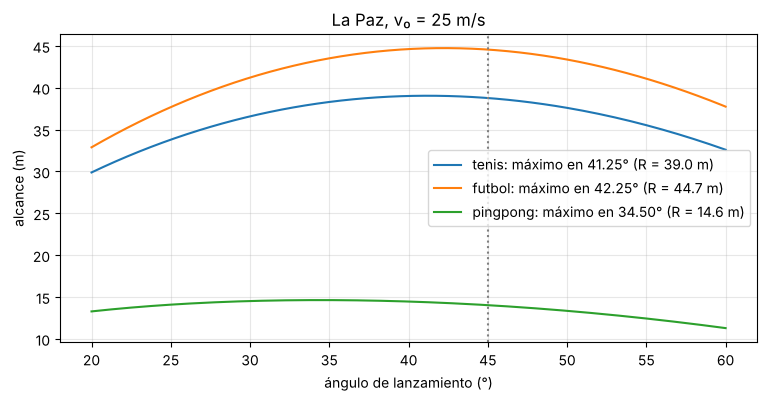

In [5]:
angulos = np.arange(20, 60.25, 0.25)
fig, ax = plt.subplots(figsize=(9, 4))
for nombre in ("tenis", "futbol", "pingpong"):
    L = LUGARES["La Paz (~3640 m)"]
    R = [numerico(25, th, 0, L["g"], L["rho"], **OBJETOS[nombre])["R"] for th in angulos]
    i = int(np.argmax(R))
    ax.plot(angulos, R, label=f"{nombre}: máximo en {angulos[i]:.2f}° (R = {R[i]:.1f} m)")
ax.axvline(45, ls=":", color="gray")
ax.set_xlabel("ángulo de lanzamiento (°)"); ax.set_ylabel("alcance (m)")
ax.set_title("La Paz, v₀ = 25 m/s"); ax.grid(alpha=.3); ax.legend(); plt.show()

## Parte 2 · Banco de problemas: regenerar la clave en Python

La página web genera los datos de cada estudiante a partir de su código, con un generador pseudoaleatorio reproducible (hash FNV‑1a + *mulberry32*). Aquí se reimplementa **el mismo generador bit a bit** y se recalculan las respuestas con las fórmulas escritas de nuevo. Si coinciden con la web, la clave del docente es confiable.

In [6]:
import math
M32 = 0xFFFFFFFF
G = 9.81

def fnv1a(texto):
    h = 2166136261
    for ch in str(texto).strip():
        h ^= ord(ch)
        h = (h * 16777619) & M32
    return h

def mulberry32(semilla):
    a = semilla & M32
    def r():
        nonlocal a
        a = (a + 0x6D2B79F5) & M32
        t = a
        t = ((t ^ (t >> 15)) * (t | 1)) & M32
        t = (t ^ ((t + (((t ^ (t >> 7)) * (t | 61)) & M32)) & M32)) & M32
        return ((t ^ (t >> 14)) & M32) / 4294967296
    return r

def pick(r, lo, hi, paso):
    n = math.floor((hi - lo) / paso + 0.5)
    return round(lo + math.floor(r() * (n + 1)) * paso, 6)

def practica(codigo):
    """Devuelve [(tema, datos, respuesta, unidad)] en el mismo orden que la web."""
    r = mulberry32(fnv1a(codigo))
    out = []
    a, t = pick(r, 1.5, 4, 0.1), pick(r, 4, 12, 1)
    out.append(("MRUV", dict(a=a, t=t), a*t**2/2, "m"))
    h, v = pick(r, 5, 40, 1), pick(r, 3, 15, 0.5)
    out.append(("Tiro horizontal", dict(h=h, v=v), v*math.sqrt(2*h/G), "m"))
    th, mu = pick(r, 25, 45, 1), pick(r, 0.10, 0.40, 0.01)
    out.append(("Plano inclinado", dict(theta=th, mu=mu), G*(math.sin(math.radians(th)) - mu*math.cos(math.radians(th))), "m/s²"))
    m, v, k = pick(r, 0.5, 3, 0.1), pick(r, 2, 8, 0.5), pick(r, 200, 1200, 50)
    out.append(("Resorte", dict(m=m, v=v, k=k), v*math.sqrt(m/k), "m"))
    m, k = pick(r, 0.2, 2, 0.1), pick(r, 20, 200, 5)
    out.append(("MAS", dict(m=m, k=k), 2*math.pi*math.sqrt(m/k), "s"))
    R1, R2, R3, V = pick(r, 10, 100, 5), pick(r, 20, 200, 10), pick(r, 20, 200, 10), pick(r, 6, 24, 1)
    out.append(("Circuito mixto", dict(R1=R1, R2=R2, R3=R3, V=V), V/(R1 + R2*R3/(R2 + R3)), "A"))
    return out

for tema, datos, resp, u in practica("1234567"):
    print(f"{tema:<16} {datos}  →  {resp:.4f} {u}")

MRUV             {'a': 1.5, 't': 6}  →  27.0000 m
Tiro horizontal  {'h': 5, 'v': 14.5}  →  14.6397 m
Plano inclinado  {'theta': 39, 'mu': 0.21}  →  4.5726 m/s²
Resorte          {'m': 2.9, 'v': 2.5, 'k': 950}  →  0.1381 m
MAS              {'m': 0.3, 'k': 125}  →  0.3078 s
Circuito mixto   {'R1': 85, 'R2': 100, 'R3': 90, 'V': 22}  →  0.1662 A


### Control 3 · ¿Python y la web dan la misma práctica?

Respuestas que muestra la web para el código de ejemplo `1234567` (pestaña *Estudiante*, botón *Ver solución*).

In [7]:
WEB_1234567 = [27.00, 14.64, 4.57, 0.138, 0.308, 0.1662]   # copiadas de la página web
py = [p[2] for p in practica("1234567")]
for i, (a, b) in enumerate(zip(py, WEB_1234567), 1):
    dif = abs(a - b) / b
    print(f"P{i}: Python = {a:.4f}   web = {b}   diferencia = {dif*100:.2f} %")
    assert dif < 0.005, f"El problema {i} no coincide con la web"
print("✔ Control 3 superado")

P1: Python = 27.0000   web = 27.0   diferencia = 0.00 %
P2: Python = 14.6397   web = 14.64   diferencia = 0.00 %
P3: Python = 4.5726   web = 4.57   diferencia = 0.06 %
P4: Python = 0.1381   web = 0.138   diferencia = 0.09 %
P5: Python = 0.3078   web = 0.308   diferencia = 0.06 %
P6: Python = 0.1662   web = 0.1662   diferencia = 0.00 %
✔ Control 3 superado


### Clave docente para toda la lista

Pegue los códigos de su curso (uno por línea). La tabla resultante es la misma que produce la pestaña *Clave docente* de la web y se puede descargar como CSV para Google Sheets.

In [8]:
import pandas as pd

CODIGOS = """
1234567
2345678
3456789
4567890
""".split()

filas = []
for c in CODIGOS:
    p = practica(c)
    filas.append({"codigo": c, **{f"P{i} ({q[3]})": round(q[2], 4) for i, q in enumerate(p, 1)}})
clave = pd.DataFrame(filas)
clave.to_csv("clave_docente.csv", index=False)
clave

,codigo,P1 (m),P2 (m),P3 (m/s²),P4 (m),P5 (s),P6 (A)
0,1234567,27.0,14.6397,4.5726,0.1381,0.3078,0.1662
1,2345678,259.2,17.5964,3.8258,0.3809,0.5310,0.2157
2,3456789,155.0,15.5087,3.2400,0.1423,1.0621,0.0807
3,4567890,20.0,32.8404,1.2274,0.2151,0.7337,0.0738


In [ ]:
# Descargar la clave (solo funciona dentro de Colab)
try:
    from google.colab import files
    files.download("clave_docente.csv")
except ImportError:
    print("Fuera de Colab: el archivo quedó guardado como clave_docente.csv")

## Parte 3 (opcional) · Pedirle a Gemini una revisión crítica desde Colab

Colab ofrece la librería `google.colab.ai` a todos los usuarios, incluido el plan gratuito, con **límites de uso mensuales** que Google no publica en cifras. Las funciones de IA de Colab requieren una cuenta de 18 años o más.

La respuesta de la IA es una opinión que se verifica, no un control: los controles 1 a 3 sí lo son. No envíe datos de estudiantes.

In [ ]:
PROMPT = '''Revisa este código como un profesor exigente de física: unidades, signos,
casos límite. Lista cada error con la línea donde aparece; si todo está bien, dilo explícitamente.

k = 0.5*rho*cd*np.pi*(d/2)**2/m
def f(t, s):
    x, y, vx, vy = s
    v = np.hypot(vx, vy)
    return [vx, vy, -k*v*vx, -g - k*v*vy]
'''
try:
    from google.colab import ai
    print(ai.generate_text(PROMPT))
except ImportError:
    print("Esta celda solo funciona dentro de Google Colab.")
except Exception as e:
    print("Colab no pudo responder (¿cupo agotado o función no disponible?):", e)

## Guardar su propia versión

- **Archivo → Guardar una copia en Drive**: copia personal editable.
- **Archivo → Guardar una copia en GitHub**: sube la versión modificada a su repositorio (Colab pedirá permiso para hacer el *commit*).

Ejercicio propuesto: agregue un séptimo problema al banco (por ejemplo, conservación del momento en un choque inelástico), impleméntelo en la web y aquí, y compruebe que ambas versiones coinciden.